# What sets the significant ExPecto-sc variants apart?

Three nested variant sets, all annotated with the same VEP pipeline (`test/`):

| set | file | variants |
|---|---|---|
| **BRIDGES** – everything sequenced in the 34-gene study | `test/new_bridges_data/` | 25,116 |
| **ExPecto** – the subset Ksenia ran through ExPecto-sc | `test/expecto_bridges_data/` | 10,066 |
| **significant** – candidate breast-cancer risk variants | `test/significant_bridges_expecto_data/` | 633 |

**How "significant" was defined** (`report_significant_variants_per_gene.ipynb`, manuscript Methods): a variant is
significant if its ExPecto-sc gene (nearest TSS) is a BRIDGES tumour suppressor and z < −1 in at least one of the
11 breast-epithelial cell types (or, for the oncogene *AKT1*, z > +1). The label is therefore a *prediction-based*
selection, not an association result. Any feature enriched among significant variants tells us what ExPecto-sc
responds to. It is not independent evidence that the variants raise risk.

**Choosing the baseline.** The right comparison is the variants that *could* have been selected: those whose
ExPecto gene is a suppressor or *AKT1* ("eligible", n = 6,406). The other 3,660 ExPecto variants were
assigned by the nearest-TSS rule to neighbouring genes (e.g. 887 *ATM*-region variants to *AP001925.1*). They
were excluded by construction, so including them would inflate every gene- and position-related contrast.

Steps:
1. Load the sets, join ExPecto-sc z-scores, and reproduce the 633 exactly.
2. Add features: VEP region and consequence, distance to the ExPecto TSS, substitution type, CpG and GC context,
   mammary-epithelial DNase peaks (ENCODE), and ClinVar classification.
3. Compare significant vs eligible baseline, crude and adjusted for TSS distance and gene.
4. Check direction: significant (predicted *loss*) vs variants with an equally large but opposite-sign effect.
5. Measure how much each feature group adds to predicting significance.

In [1]:
import glob
import gzip
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from statsmodels.discrete.conditional_models import ConditionalLogit
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

ROOT = pathlib.Path('/storage/mathelierarea/processed/eirikhoy/action_var')
TEST = ROOT / 'test'
SEQ_CACHE = ROOT / 'results/expecto_bridges34_hg38_windows.json'
CLINVAR_CACHE = ROOT / 'results/expecto_bridges34_clinvar.csv'
FIGDIR = pathlib.Path('significant_vs_baseline_figures')
FIGDIR.mkdir(exist_ok=True)

# Breast-epithelial cell types and gene roles exactly as used to define the significant set
# (report_significant_variants_per_gene.ipynb), including its gene-name spellings.
EPI = ['Lumsec_major', 'Lumsec_myo', 'Lumsec_basal', 'Lumsec_KIT', 'Lumsec_lac', 'Lumsec_prol', 'Lumsec_HLA',
       'LummHR_major', 'LummHR_SCGB', 'LummHR_active', 'basal']
SUPPRESSOR = ['ATM', 'BARD1', 'BRCA1', 'BRCA2', 'BRIP1', 'CDH1', 'CHEK2', 'FANCM', 'MEN1', 'MLH1', 'MRE11A',
              'MSH2', 'MSH6', 'MUTYH', 'NBN', 'NF1', 'PALB2', 'PMS2', 'PTEN', 'RAD50', 'RAD51C', 'RAD51D',
              'RECQL', 'STK11', 'TP53', 'XRCC2', 'FAM175A/ABRAXAS1', 'GEN1']
ONCOGENE = ['AKT1']

# Same region colours as analyze_new_bridges34_variants.ipynb.
REGIONS = {
    'promoter (≤1 kb)': '#eb6834',
    "5' UTR": '#1baf7a',
    'coding': '#eda100',
    'splice site / region': '#e87ba4',
    'intron': '#008300',
    "3' UTR": '#6250d6',
    'distal (>5 kb)': '#b5b4ad',
}
SIG_C, BASE_C, ALT_C = '#eb6834', '#2a78d6', '#898781'

INK, SECONDARY, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': SECONDARY,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': SECONDARY, 'ytick.labelcolor': SECONDARY,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.titlesize': 16, 'figure.titleweight': 'bold',
})


def save(fig, name):
    fig.savefig(FIGDIR / f'{name}.png', dpi=200, bbox_inches='tight')

## 1. Load the three sets and reproduce the selection

In [2]:
bridges = pd.read_csv(TEST / 'new_bridges_data/bridges_34genes_vep_report_annotated.csv')
expecto = pd.read_csv(TEST / 'expecto_bridges_data/vep_report_annotated.csv')
significant = pd.read_csv(TEST / 'significant_bridges_expecto_data/vep_report_annotated.csv')

print(f'BRIDGES {len(bridges):,} | ExPecto {len(expecto):,} | significant {len(significant):,}')
print(f'significant ⊂ ExPecto: {significant.VariantID.isin(expecto.VariantID).all()};  '
      f'ExPecto ⊂ BRIDGES: {expecto.VariantID.isin(bridges.VariantID).all()}')

BRIDGES 25,116 | ExPecto 10,066 | significant 633
significant ⊂ ExPecto: True;  ExPecto ⊂ BRIDGES: True


ExPecto-sc metadata (nearest TSS, distance, gene) is in hg38 in `test/expecto_bridges_data/bridges_34_genes_hg38.csv`.
The z-scores are keyed by the original hg19 IDs. The hg19 run file has the same rows in the same order, so
the IDs map one to one. Ties (a variant equidistant to two TSSs) keep the nearest, as in the original analysis.

In [3]:
meta = pd.read_csv(TEST / 'expecto_bridges_data/bridges_34_genes_hg38.csv')
meta19 = pd.read_csv(ROOT / 'data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv')
assert (meta.gene_name.values == meta19.gene_name.values).all() and (meta.dist.values == meta19.dist.values).all()
meta['SNP_hg19'] = meta19.SNP.values
meta = meta.sort_values(['SNP', 'dist']).drop_duplicates('SNP')

z = pd.read_csv(ROOT / 'data/eirik/Seqweaver_bridges__breast.csv', index_col='SNP').drop(columns='macro_mean')
meta = meta.join(z[EPI], on='SNP_hg19')

df = expecto.merge(meta[['SNP', 'gene_name', 'strand', 'tss', 'dist', 'cage_used', *EPI]],
                   left_on='VariantID', right_on='SNP').drop(columns='SNP')
df['role'] = np.select([df.gene_name.isin(SUPPRESSOR), df.gene_name.isin(ONCOGENE)],
                       ['suppressor', 'oncogene'], 'unclassified')

ze = df[EPI]
df['significant'] = df.VariantID.isin(significant.VariantID)
reproduced = np.select([df.role == 'suppressor', df.role == 'oncogene'],
                       [(ze < -1).any(axis=1), (ze > 1).any(axis=1)], False)
assert (reproduced == df.significant).all()
print('selection rule reproduces the 633 significant variants exactly')

df['eligible'] = df.role != 'unclassified'
df['epi_min_z'], df['epi_max_z'] = ze.min(axis=1), ze.max(axis=1)
# Large epithelial effect, but only in the direction opposite to the risk hypothesis.
df['discordant_large'] = df.eligible & ~df.significant & (ze.abs() > 1).any(axis=1)
pd.crosstab(df.role, df.significant, margins=True).rename(columns={True: 'significant', False: 'not'})

selection rule reproduces the 633 significant variants exactly


significant,not,significant,All
role,,,
oncogene,66,0,66
suppressor,5707,633,6340
unclassified,3660,0,3660
All,9433,633,10066


**Two artefacts of the selection to keep in mind**

- `cage_used` looks like a perfect predictor (100% of significant variants vs 85% of the rest), but all
  1,403 non-CAGE TSSs belong to unclassified genes. It is fully explained by eligibility and carries no signal.
- The suppressor list in the original notebook spells one gene `'FAM175A/ABRAXAS1'`, which never matches the
  gene name `FAM175A`. Its 24 variants were treated as unclassified. The cell below shows whether this
  changed the result.

In [4]:
print(pd.crosstab(df.role, df.cage_used))
fam = df[df.gene_name == 'FAM175A']
print(f'\nFAM175A: {len(fam)} variants, {(fam[EPI] < -1).any(axis=1).sum()} would be significant '
      'if the gene had been classified as a suppressor')

cage_used     False  True 
role                      
oncogene          0     66
suppressor        0   6340
unclassified   1403   2257

FAM175A: 24 variants, 3 would be significant if the gene had been classified as a suppressor


## 2. Features

All features are computed for the 10,066 ExPecto variants:

- **region / consequence**: VEP on the BRIDGES gene's MANE transcript (from the annotation pipeline).
- **TSS distance**: signed distance to the TSS ExPecto-sc used (positive = downstream, into the gene).
- **substitution**: the 6 pyrimidine-collapsed classes, transition vs transversion, **CpG** (the C or G of a CpG
  dinucleotide) and **GC content** of the ±50 bp window (hg38 sequence from the UCSC API, cached in `results/`).
- **DNase**: overlap with mammary-epithelial DNase-seq narrowPeaks from ENCODE (`resources/ENCFF*.bed.gz`,
  16 files). We record whether any peak overlaps and how many files have one.
- **ClinVar**: clinical significance (`resources/clinvar.vcf.gz`, GRCh38), matched on chrom/pos/ref/alt.

In [5]:
# Signed distance to the ExPecto TSS, in the direction of transcription.
df['tss_signed'] = (df.pos - (df.tss + 1)) * np.where(df.strand == '-', -1, 1)
df['log10_dist'] = np.log10(df.dist.clip(lower=1))
DIST_BINS = [0, 250, 500, 1000, 2000, 5000, 10000, 20001]
DIST_LABELS = ['<250 bp', '250-500 bp', '0.5-1 kb', '1-2 kb', '2-5 kb', '5-10 kb', '10-20 kb']
df['dist_bin'] = pd.cut(df.dist, DIST_BINS, labels=DIST_LABELS, right=False)

# hg38 sequence around the variants: one UCSC request per cluster of variants.
FLANK = 60
if not SEQ_CACHE.exists():
    windows = []
    for chrom, g in df.groupby('chrom'):
        p = np.sort(g.pos.values)
        breaks = np.where(np.diff(p) > 5000)[0]
        for s, e in zip(np.r_[p[0], p[breaks + 1]], np.r_[p[breaks], p[-1]]):
            start0, end0 = int(s) - 1 - FLANK, int(e) + FLANK
            r = requests.get(f'https://api.genome.ucsc.edu/getData/sequence?genome=hg38;chrom={chrom};'
                             f'start={start0};end={end0}', timeout=120)
            windows.append({'chrom': chrom, 'start0': start0, 'dna': r.json()['dna'].upper()})
    SEQ_CACHE.write_text(json.dumps(windows))
windows = json.loads(SEQ_CACHE.read_text())


def context(chrom, pos, flank):
    for w in windows:
        i = pos - 1 - w['start0']
        if w['chrom'] == chrom and 0 <= i < len(w['dna']):
            return w['dna'][i - flank:i + flank + 1]


df['tri'] = [context(c, p, 1) for c, p in zip(df.chrom, df.pos)]
win = [context(c, p, 50) for c, p in zip(df.chrom, df.pos)]
df['gc_100bp'] = [(s.count('G') + s.count('C')) / len(s) for s in win]
print(f'reference base matches hg38 for {(df.tri.str[1] == df.Ref).mean():.2%} of variants')

COMP = str.maketrans('ACGT', 'TGCA')
pyr = df.Ref.isin(['C', 'T'])
df['substitution'] = np.where(pyr, df.Ref + '>' + df.Alt,
                              df.Ref.str.translate(COMP) + '>' + df.Alt.str.translate(COMP))
df['transition'] = df.substitution.isin(['C>T', 'T>C'])
df['cpg'] = ((df.Ref == 'C') & (df.tri.str[2] == 'G')) | ((df.Ref == 'G') & (df.tri.str[0] == 'C'))
df['cpg_transition'] = df.cpg & df.transition

# ENCODE mammary epithelial DNase peaks.
peaks = []
for f in sorted(glob.glob(str(ROOT / 'resources/ENCFF*.bed.gz'))):
    p = pd.read_csv(f, sep='\t', header=None, usecols=[0, 1, 2], names=['chrom', 'start', 'end'])
    peaks.append(p[p.chrom.isin(df.chrom.unique())])


def in_peak(p, chrom, pos0):
    # Peaks sorted by start; a position is covered if the running max end of peaks starting at or before it exceeds it.
    q = p[p.chrom == chrom].sort_values('start')
    if q.empty:
        return np.zeros(len(pos0), bool)
    idx = np.searchsorted(q.start.values, pos0, side='right') - 1
    return (idx >= 0) & (np.maximum.accumulate(q.end.values)[idx.clip(0)] > pos0)


df['dnase_files'] = 0
for p in peaks:
    for chrom, g in df.groupby('chrom'):
        df.loc[g.index, 'dnase_files'] += in_peak(p, chrom, g.pos.values - 1)
df['dnase_any'] = df.dnase_files > 0
print(f'{len(peaks)} DNase files; {df.dnase_any.mean():.1%} of ExPecto variants overlap at least one peak')

reference base matches hg38 for 99.99% of variants


16 DNase files; 9.2% of ExPecto variants overlap at least one peak


In [6]:
if not CLINVAR_CACHE.exists():
    keys = set(zip(df.chrom.str[3:], df.pos, df.Ref, df.Alt))
    rows = []
    with gzip.open(ROOT / 'resources/clinvar.vcf.gz', 'rt') as fh:
        for line in fh:
            if line[0] == '#':
                continue
            c, p, _, r, a, _, _, info = line.rstrip('\n').split('\t', 7)
            if (c, int(p), r, a) in keys:
                d = dict(x.split('=', 1) for x in info.split(';') if '=' in x)
                rows.append((f'{c}_{p}_{r}_{a}', d.get('CLNSIG'), d.get('CLNREVSTAT')))
    pd.DataFrame(rows, columns=['VariantID', 'CLNSIG', 'CLNREVSTAT']).to_csv(CLINVAR_CACHE, index=False)
clinvar = pd.read_csv(CLINVAR_CACHE).drop_duplicates('VariantID')


def clinvar_class(s):
    if pd.isna(s):
        return 'not in ClinVar'
    s = s.lower()
    if s.startswith('conflicting'):
        return 'conflicting'
    if 'pathogenic' in s:
        return 'pathogenic / likely'
    if 'benign' in s:
        return 'benign / likely'
    if 'uncertain' in s:
        return 'VUS'
    return 'other'


df = df.merge(clinvar, on='VariantID', how='left')
df['clinvar'] = df.CLNSIG.map(clinvar_class)
print(f'{df.CLNSIG.notna().sum():,} of {len(df):,} ExPecto variants are in ClinVar')
df.clinvar.value_counts().to_frame('variants')

10,040 of 10,066 ExPecto variants are in ClinVar


,variants
clinvar,
VUS,3443
benign / likely,3394
conflicting,2676
pathogenic / likely,525
not in ClinVar,26
other,2


## 3. Where in the selection funnel do variants drop out?

Region composition of each set. The ExPecto set is a SNV-only subset of BRIDGES (almost all in ClinVar), so its
composition is close to BRIDGES. The big shift happens between eligible and significant.

,BRIDGES,ExPecto,eligible,significant
region,,,,
promoter (≤1 kb),0.8,2.0,2.3,11.1
5' UTR,0.8,1.9,2.9,10.9
coding,84.4,82.6,80.8,65.2
splice site / region,8.1,7.7,7.7,7.6
intron,5.3,5.4,6.2,5.2
3' UTR,0.4,0.4,0.0,0.0
distal (>5 kb),0.1,0.0,0.0,0.0


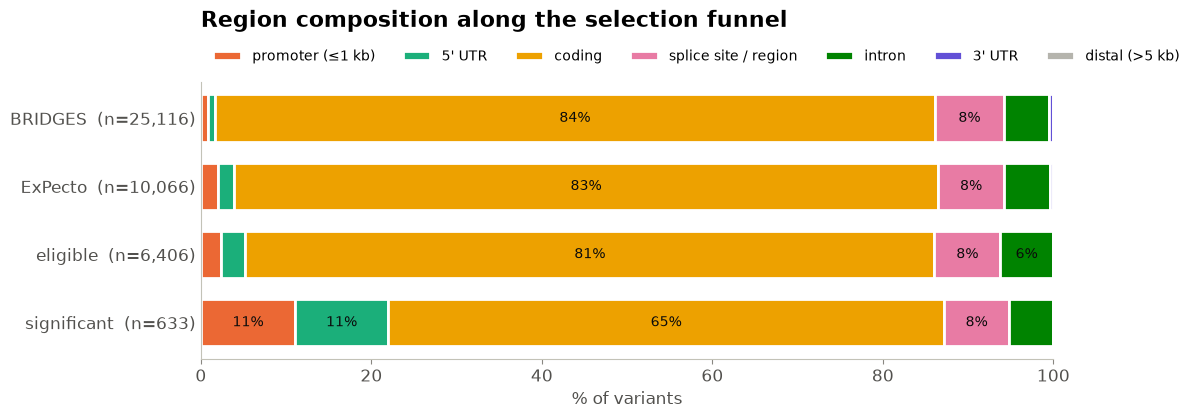

In [7]:
eligible = df[df.eligible]
base = eligible[~eligible.significant]
sig = eligible[eligible.significant]
sets = {'BRIDGES': bridges, 'ExPecto': df, 'eligible': eligible, 'significant': sig}
USED = [r for r in REGIONS if any((s.region == r).any() for s in sets.values())]
comp = pd.DataFrame({k: v.region.value_counts(normalize=True) for k, v in sets.items()}).reindex(USED).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 3.6))
y = np.arange(len(sets))[::-1]
left = np.zeros(len(sets))
for r in USED:
    ax.barh(y, comp.loc[r], left=left, color=REGIONS[r], height=0.7, label=r, edgecolor='white', lw=2)
    for yi, l, w in zip(y, left, comp.loc[r]):
        if w >= 6:
            ax.text(l + w / 2, yi, f'{w:.0f}%', ha='center', va='center', fontsize=10, color=INK)
    left += comp.loc[r].values
ax.set_yticks(y, [f'{k}  (n={len(v):,})' for k, v in sets.items()])
ax.set_xlim(0, 100)
ax.set_xlabel('% of variants')
ax.tick_params(axis='y', length=0)
ax.legend(ncols=len(USED), frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), fontsize=10)
fig.suptitle('Region composition along the selection funnel', x=0.125, ha='left', y=1.08)
save(fig, 'region_composition_by_set')
comp.round(1)

## 4. Crude enrichment: significant vs eligible baseline

One row per feature level. Each row has a Fisher exact test (level vs all other levels), an odds ratio with a
95% CI (Woolf, +0.5 continuity correction), and a Benjamini–Hochberg q-value across all rows.

In [8]:
CODING_DETAIL = ['missense', 'synonymous', 'stop gained', 'start / stop lost', 'canonical splice site', 'splice region']
eligible = eligible.assign(
    detail_f=eligible.detail.where(eligible.detail.isin(CODING_DETAIL), 'non-coding / other'),
    direction=np.where(eligible.tss_signed < 0, 'upstream of TSS', 'downstream of TSS'),
    dnase_f=np.where(eligible.dnase_any, 'in DNase peak', 'no DNase peak'),
    cpg_f=np.where(eligible.cpg, 'CpG site', 'non-CpG'),
    tstv=np.where(eligible.transition, 'transition', 'transversion'),
)
FEATURES = {
    'region': 'region', 'consequence': 'detail_f', 'TSS distance': 'dist_bin', 'TSS side': 'direction',
    'substitution': 'substitution', 'Ts/Tv': 'tstv', 'CpG': 'cpg_f', 'DNase (mammary epi)': 'dnase_f',
    'ClinVar': 'clinvar',
}


def or_ci(a, b, c, d):
    a, b, c, d = (x + 0.5 for x in (a, b, c, d))
    lor, se = np.log(a * d / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return np.exp(lor), np.exp(lor - 1.96 * se), np.exp(lor + 1.96 * se)


def enrichment(data, flag, features):
    rows = []
    n1, n0 = data[flag].sum(), (~data[flag]).sum()
    for name, col in features.items():
        for level in data[col].dropna().unique():
            x = data[col] == level
            a, b = (x & data[flag]).sum(), (x & ~data[flag]).sum()
            c, d = n1 - a, n0 - b
            OR, lo, hi = or_ci(a, b, c, d)
            rows.append({'feature': name, 'level': str(level), 'n_sig': a, '% sig': 100 * a / n1,
                         'n_base': b, '% base': 100 * b / n0, 'OR': OR, 'CI_lo': lo, 'CI_hi': hi,
                         'p': stats.fisher_exact([[a, b], [c, d]])[1]})
    out = pd.DataFrame(rows)
    out['q'] = multipletests(out.p, method='fdr_bh')[1]
    return out


crude = enrichment(eligible, 'significant', FEATURES)
fmt = {'% sig': '{:.1f}', '% base': '{:.1f}', 'OR': '{:.2f}', 'CI_lo': '{:.2f}', 'CI_hi': '{:.2f}',
       'p': '{:.1e}', 'q': '{:.1e}'}
crude.sort_values(['feature', 'OR'], ascending=[True, False]).style.format(fmt).hide(axis='index')

feature,level,n_sig,% sig,n_base,% base,OR,CI_lo,CI_hi,p,q
ClinVar,not in ClinVar,4,0.6,19,0.3,2.11,0.75,5.90,2.8e-01,3.4e-01
ClinVar,other,0,0.0,2,0.0,1.82,0.09,38.00,1.0e+00,1.0e+00
ClinVar,VUS,241,38.1,1874,32.5,1.28,1.08,1.52,5.0e-03,7.7e-03
ClinVar,pathogenic / likely,35,5.5,307,5.3,1.05,0.74,1.51,7.8e-01,8.7e-01
ClinVar,benign / likely,199,31.4,1944,33.7,0.90,0.76,1.08,2.7e-01,3.3e-01
ClinVar,conflicting,154,24.3,1627,28.2,0.82,0.68,0.99,4.0e-02,5.7e-02
CpG,CpG site,183,28.9,696,12.1,2.97,2.46,3.59,3.1e-26,1.3e-25
CpG,non-CpG,450,71.1,5077,87.9,0.34,0.28,0.41,3.1e-26,1.3e-25
DNase (mammary epi),in DNase peak,310,49.0,455,7.9,11.21,9.33,13.45,1.5e-137,2.1e-136
DNase (mammary epi),no DNase peak,323,51.0,5318,92.1,0.09,0.07,0.11,1.5e-137,2.1e-136


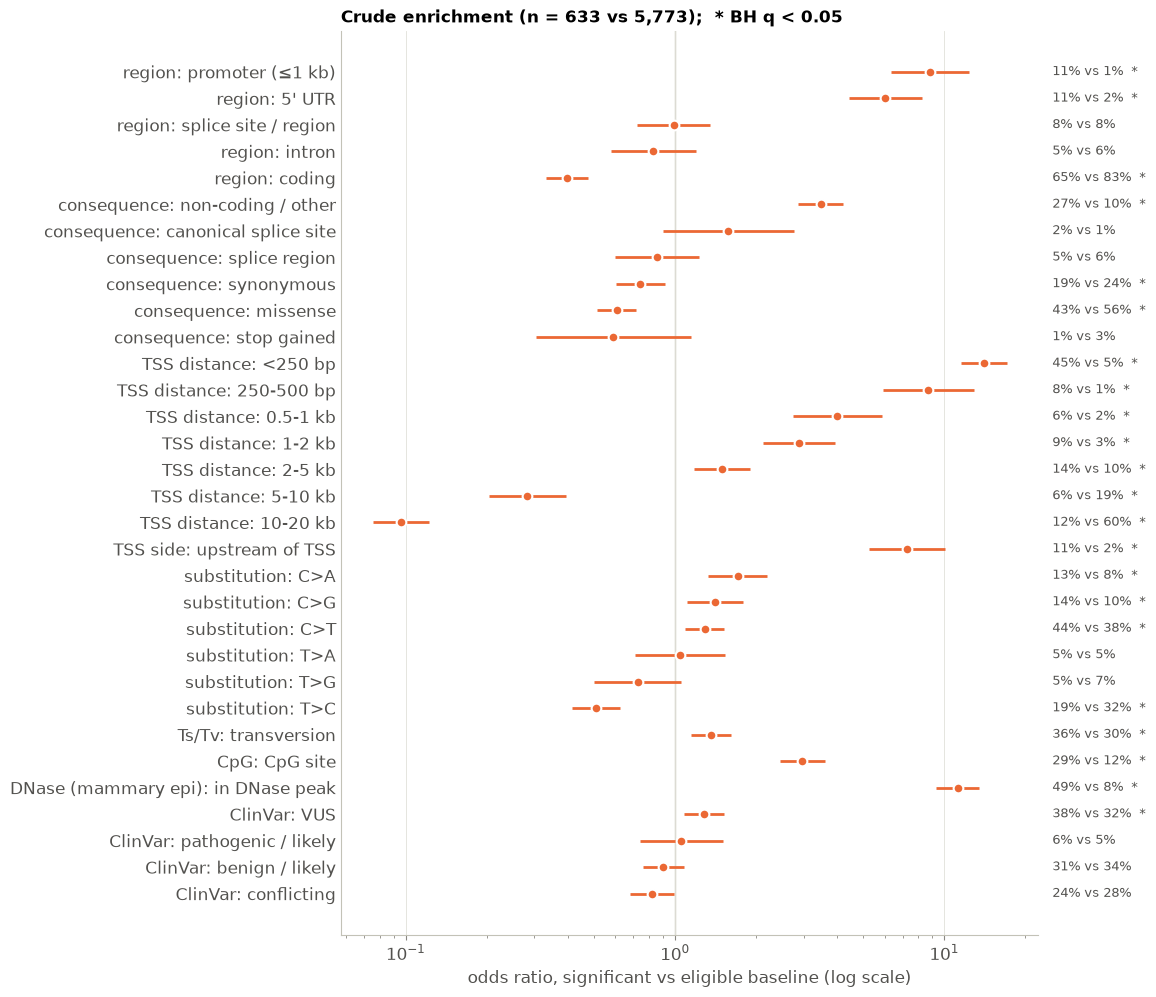

In [9]:
def forest(ax, table, color, label=None, offset=0.0, show_labels=True):
    t = table.reset_index(drop=True)
    y = np.arange(len(t))[::-1] + offset
    ax.errorbar(t.OR, y, xerr=[t.OR - t.CI_lo, t.CI_hi - t.OR], fmt='o', color=color, ms=7,
                elinewidth=2, capsize=0, label=label, mec='white', mew=1.5)
    if show_labels:
        ax.set_yticks(np.arange(len(t))[::-1], [f'{f}: {l}' for f, l in zip(t.feature, t.level)])
    ax.axvline(1, color=AXIS, lw=1, zorder=0)
    ax.set_xscale('log')
    ax.grid(axis='x', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0)


ORDER = list(FEATURES)
# Binary features: show only the level of interest (the complement is its mirror image).
COMPLEMENTS = ['not in ClinVar', 'no DNase peak', 'non-CpG', 'downstream of TSS', 'transition']
shown = crude[(crude.n_sig + crude.n_base >= 30) & ~crude.level.isin(COMPLEMENTS)].copy()
shown['fo'] = shown.feature.map(ORDER.index)
shown = shown.sort_values(['fo', 'OR'], ascending=[True, False])

fig, ax = plt.subplots(figsize=(9, 0.32 * len(shown) + 1.5))
forest(ax, shown, SIG_C)
for yi, (_, r) in zip(np.arange(len(shown))[::-1], shown.iterrows()):
    ax.text(1.02, yi, f'{r["% sig"]:.0f}% vs {r["% base"]:.0f}%' + ('  *' if r.q < 0.05 else ''),
            transform=ax.get_yaxis_transform(), va='center', fontsize=9, color=SECONDARY)
ax.set_xlabel('odds ratio, significant vs eligible baseline (log scale)')
ax.set_title(f'Crude enrichment (n = {eligible.significant.sum()} vs {(~eligible.significant).sum():,});  '
             '* BH q < 0.05', fontsize=12)
save(fig, 'crude_enrichment_forest')

## 5. Distance to the TSS dominates

ExPecto-type models weight sequence by distance to the TSS, so predicted effects shrink with distance. If
significant variants are simply closer to the TSS, many of the crude enrichments above (promoter, 5' UTR, CpG,
DNase) could be the same signal seen several times.

Mann-Whitney U p = 6.5e-198;  59% of significant vs 8% of baseline within 1 kb


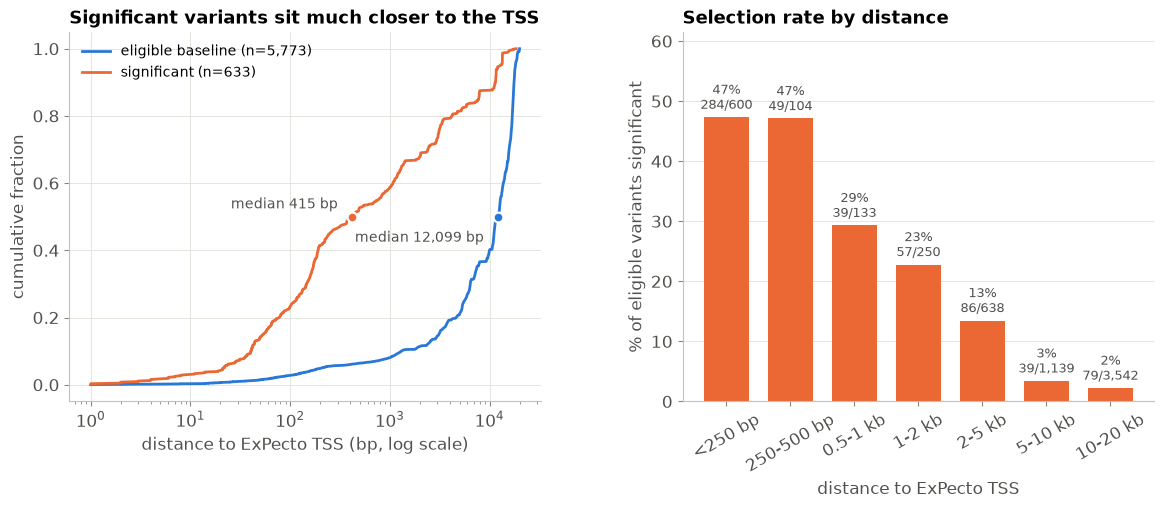

In [10]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'wspace': 0.3})
for d, lab, c in [(base, f'eligible baseline (n={len(base):,})', BASE_C), (sig, f'significant (n={len(sig)})', SIG_C)]:
    x = np.sort(d.dist.clip(lower=1).values)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=c, lw=2, label=lab)
    ax.annotate(f'median {np.median(x):,.0f} bp', (np.median(x), 0.5), xytext=(-10, 6) if c == SIG_C else (-10, -18),
                ha='right', textcoords='offset points', fontsize=10, color=SECONDARY)
    ax.plot(np.median(x), 0.5, 'o', color=c, ms=7, mec='white', mew=1.5)
ax.set_xscale('log')
ax.set_xlabel('distance to ExPecto TSS (bp, log scale)')
ax.set_ylabel('cumulative fraction')
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', fontsize=10)
ax.set_title('Significant variants sit much closer to the TSS')

rate = eligible.groupby('dist_bin', observed=False).significant.agg(['sum', 'count'])
rate['pct'] = 100 * rate['sum'] / rate['count']
ax2.bar(rate.index.astype(str), rate.pct, color=SIG_C, width=0.7)
ax2.bar_label(ax2.containers[0], labels=[f'{p:.0f}%\n{s}/{n:,}' for p, s, n in zip(rate.pct, rate['sum'], rate['count'])],
              padding=3, fontsize=9, color=SECONDARY)
ax2.set_ylim(0, rate.pct.max() * 1.3)
ax2.set_ylabel('% of eligible variants significant')
ax2.set_xlabel('distance to ExPecto TSS')
ax2.tick_params(axis='x', rotation=30)
ax2.grid(axis='y', color=GRID, lw=0.6)
ax2.set_axisbelow(True)
ax2.set_title('Selection rate by distance')
save(fig, 'tss_distance')

mw = stats.mannwhitneyu(sig.dist, base.dist)
print(f'Mann-Whitney U p = {mw.pvalue:.1e};  '
      f'{(sig.dist < 1000).mean():.0%} of significant vs {(base.dist < 1000).mean():.0%} of baseline within 1 kb')

Signed position: are significant variants preferentially upstream (promoter) or just downstream (5' UTR,
first exons) of the TSS?

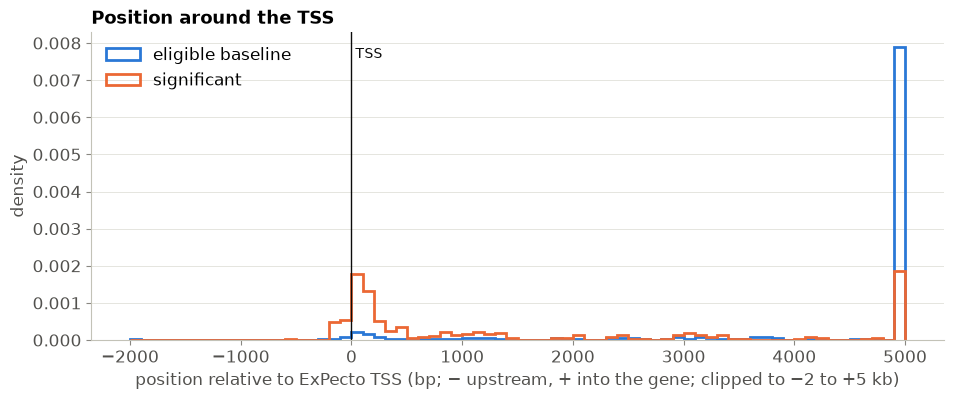

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.arange(-2000, 5001, 100)
for d, lab, c in [(base, 'eligible baseline', BASE_C), (sig, 'significant', SIG_C)]:
    ax.hist(d.tss_signed.clip(-2000, 5000), bins=bins, density=True, histtype='step', lw=2, color=c, label=lab)
ax.axvline(0, color=INK, lw=1)
ax.text(0, ax.get_ylim()[1] * 0.95, ' TSS', fontsize=10, color=INK, va='top')
ax.set_xlabel('position relative to ExPecto TSS (bp; − upstream, + into the gene; clipped to −2 to +5 kb)')
ax.set_ylabel('density')
ax.legend(frameon=False)
ax.grid(axis='y', color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.set_title('Position around the TSS')
save(fig, 'tss_signed_position')

## 6. Which enrichments survive adjustment?

**Mantel–Haenszel odds ratios** for binary features, stratified jointly by TSS-distance bin and gene, so a
variant is compared only with baseline variants of the same gene at a similar distance. Strata without both
significant and baseline variants carry no information and are dropped.

In [12]:
e = eligible.copy()
e['stratum'] = e.gene_name + '|' + e.dist_bin.astype(str)
BINARY = {
    'promoter (≤1 kb)': e.region == 'promoter (≤1 kb)',
    "5' UTR": e.region == "5' UTR",
    'coding': e.region == 'coding',
    'intron': e.region == 'intron',
    'splice site / region': e.region == 'splice site / region',
    'missense': e.detail == 'missense',
    'synonymous': e.detail == 'synonymous',
    'stop gained': e.detail == 'stop gained',
    'upstream of TSS': e.tss_signed < 0,
    'CpG site': e.cpg,
    'transition': e.transition,
    'CpG transition': e.cpg_transition,
    'GC ≥ 60% (±50 bp)': e.gc_100bp >= 0.6,
    'DNase peak (mammary epi)': e.dnase_any,
    'ClinVar pathogenic / likely': e.clinvar == 'pathogenic / likely',
    'ClinVar benign / likely': e.clinvar == 'benign / likely',
    'ClinVar VUS': e.clinvar == 'VUS',
    'ClinVar conflicting': e.clinvar == 'conflicting',
}


def mantel_haenszel(flag, x, strata):
    tables = []
    for _, g in pd.DataFrame({'y': flag, 'x': x, 's': strata}).groupby('s'):
        t = np.array([[(g.x & g.y).sum(), (g.x & ~g.y).sum()], [(~g.x & g.y).sum(), (~g.x & ~g.y).sum()]])
        if t[:, 0].sum() and t[:, 1].sum() and t[0].sum() and t[1].sum():
            tables.append(t.astype(float))
    st = StratifiedTable(tables)
    lo, hi = st.oddsratio_pooled_confint()
    return st.oddsratio_pooled, lo, hi, st.test_null_odds().pvalue


rows = []
for name, x in BINARY.items():
    x = x.values
    y = e.significant.values
    a, b, c, d = (x & y).sum(), (x & ~y).sum(), (~x & y).sum(), (~x & ~y).sum()
    OR, lo, hi = or_ci(a, b, c, d)
    mh = mantel_haenszel(e.significant.values, x, e.stratum.values)
    rows.append({'feature': name, 'level': '', '% sig': 100 * a / y.sum(), '% base': 100 * b / (~y).sum(),
                 'crude OR': OR, 'crude lo': lo, 'crude hi': hi,
                 'adj OR': mh[0], 'adj lo': mh[1], 'adj hi': mh[2], 'adj p': mh[3]})
adj = pd.DataFrame(rows)
adj['adj q'] = multipletests(adj['adj p'], method='fdr_bh')[1]
adj.style.format({c: '{:.2f}' for c in adj.columns if 'OR' in c or c.endswith(('lo', 'hi'))} |
                 {'% sig': '{:.1f}', '% base': '{:.1f}', 'adj p': '{:.1e}', 'adj q': '{:.1e}'}).hide(axis='index')

feature,level,% sig,% base,crude OR,crude lo,crude hi,adj OR,adj lo,adj hi,adj p,adj q
promoter (≤1 kb),,11.1,1.4,8.85,6.35,12.32,0.99,0.65,1.49,9.5e-01,9.5e-01
5' UTR,,10.9,2.0,6.03,4.42,8.22,0.86,0.58,1.27,4.4e-01,8.3e-01
coding,,65.2,82.5,0.40,0.33,0.47,1.05,0.81,1.36,7.0e-01,8.3e-01
intron,,5.2,6.3,0.83,0.58,1.19,0.82,0.52,1.30,3.8e-01,8.3e-01
splice site / region,,7.6,7.7,0.99,0.72,1.34,1.21,0.84,1.75,3.0e-01,7.7e-01
missense,,43.3,55.7,0.61,0.51,0.72,1.05,0.85,1.30,6.4e-01,8.3e-01
synonymous,,19.0,24.0,0.74,0.60,0.91,0.96,0.74,1.23,7.4e-01,8.3e-01
stop gained,,1.4,2.5,0.59,0.30,1.14,1.32,0.60,2.90,5.0e-01,8.3e-01
upstream of TSS,,10.6,1.6,7.24,5.23,10.02,0.91,0.61,1.37,6.6e-01,8.3e-01
CpG site,,28.9,12.1,2.97,2.46,3.59,2.55,1.99,3.27,1.3e-14,2.3e-13


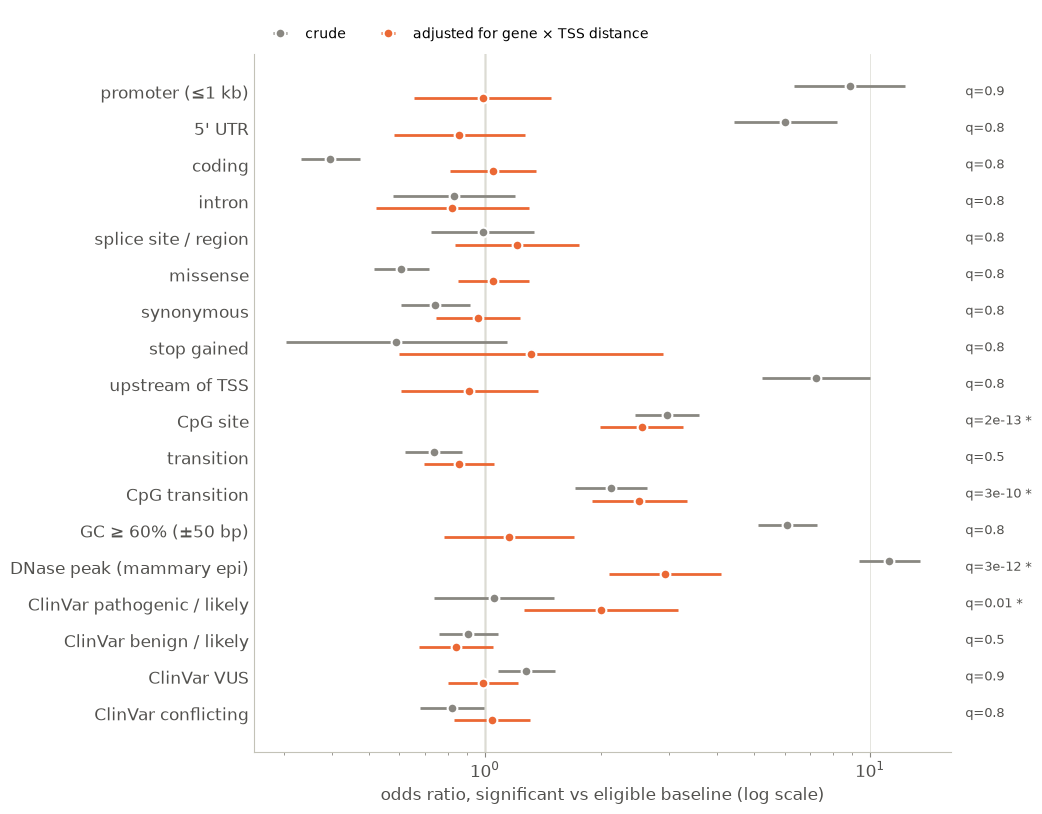

In [13]:
fig, ax = plt.subplots(figsize=(9, 0.42 * len(adj) + 1.5))
t = adj.assign(OR=adj['crude OR'], CI_lo=adj['crude lo'], CI_hi=adj['crude hi'])
forest(ax, t, ALT_C, label='crude', offset=0.17)
t = adj.assign(OR=adj['adj OR'], CI_lo=adj['adj lo'], CI_hi=adj['adj hi'])
forest(ax, t, SIG_C, label='adjusted for gene × TSS distance', offset=-0.17)
ax.set_yticks(np.arange(len(adj))[::-1], adj.feature)
for yi, q in zip(np.arange(len(adj))[::-1], adj['adj q']):
    ax.text(1.02, yi, f'q={q:.1g}' + (' *' if q < 0.05 else ''), transform=ax.get_yaxis_transform(),
            va='center', fontsize=9, color=SECONDARY)
ax.set_xlabel('odds ratio, significant vs eligible baseline (log scale)')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2, fontsize=10)
ax.set_title(' ', pad=22)
save(fig, 'adjusted_enrichment_forest')

**Joint model.** A conditional logistic regression stratified by gene (each gene its own baseline). It includes
log TSS distance plus all features together, so each coefficient is adjusted for the others. Reference
levels: coding region, non-CpG, transversion, no DNase peak, not pathogenic.

In [14]:
X = pd.DataFrame({
    'log10 TSS distance': e.log10_dist,
    'upstream of TSS': (e.tss_signed < 0).astype(float),
    'promoter (≤1 kb)': (e.region == 'promoter (≤1 kb)').astype(float),
    "5' UTR": (e.region == "5' UTR").astype(float),
    'intron / splice': e.region.isin(['intron', 'splice site / region']).astype(float),
    'CpG site': e.cpg.astype(float),
    'transition': e.transition.astype(float),
    'GC fraction (±50 bp, per 10%)': e.gc_100bp * 10,
    'DNase files overlapping (per file)': e.dnase_files.astype(float),
    'ClinVar pathogenic / likely': (e.clinvar == 'pathogenic / likely').astype(float),
})
fit = ConditionalLogit(e.significant.astype(int).values, X.values, groups=e.gene_name.values).fit(disp=0)
ci = fit.conf_int()
clogit = pd.DataFrame({'OR': np.exp(fit.params), '2.5%': np.exp(ci[:, 0]), '97.5%': np.exp(ci[:, 1]),
                       'p': fit.pvalues}, index=X.columns)
clogit.style.format({'OR': '{:.2f}', '2.5%': '{:.2f}', '97.5%': '{:.2f}', 'p': '{:.1e}'})

/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/statsmodels/discrete/conditional_models.py:80: UserWarning: Dropped 3 groups and 91 observations for having no within-group variance
  warnings.warn(msg)


,OR,2.5%,97.5%,p
log10 TSS distance,0.22,0.18,0.28,1.1e-38
upstream of TSS,0.74,0.14,3.88,7.2e-01
promoter (≤1 kb),0.20,0.04,1.11,6.6e-02
5' UTR,0.35,0.22,0.57,1.8e-05
intron / splice,1.30,0.96,1.76,9.4e-02
CpG site,2.46,1.93,3.13,2.8e-13
transition,0.87,0.70,1.08,2.0e-01
"GC fraction (±50 bp, per 10%)",0.92,0.79,1.09,3.4e-01
DNase files overlapping (per file),1.19,1.14,1.23,2.4e-17
ClinVar pathogenic / likely,1.74,1.13,2.68,1.2e-02


## 7. Genes

Per gene: the fraction of eligible variants that are significant, against the fraction within 1 kb of the TSS.
If genes differ mainly because their variants sit at different distances from the TSS, the two should track
each other.

,n,n_sig,near,median_dist,pct_sig,p,q
gene_name,,,,,,,
PTEN,24,14,100%,848,58.3,5.7e-09,2.6e-08
CDH1,36,17,14%,"1,070",47.2,9.4e-09,3.8e-08
NF1,8,3,100%,376,37.5,3.7e-02,5.4e-02
FANCM,222,57,42%,"1,255",25.7,4.3e-12,2.4e-11
MSH2,499,112,42%,"5,373",22.4,4.8e-18,4.5e-17
RAD50,91,20,40%,"2,362",22.0,5.2e-04,1.0e-03
BRCA1,128,27,22%,"5,474",21.1,1.2e-04,3.1e-04
MLH1,238,50,32%,"7,491",21.0,1.7e-07,6.1e-07
MEN1,162,32,40%,"2,535",19.8,1.4e-04,3.2e-04


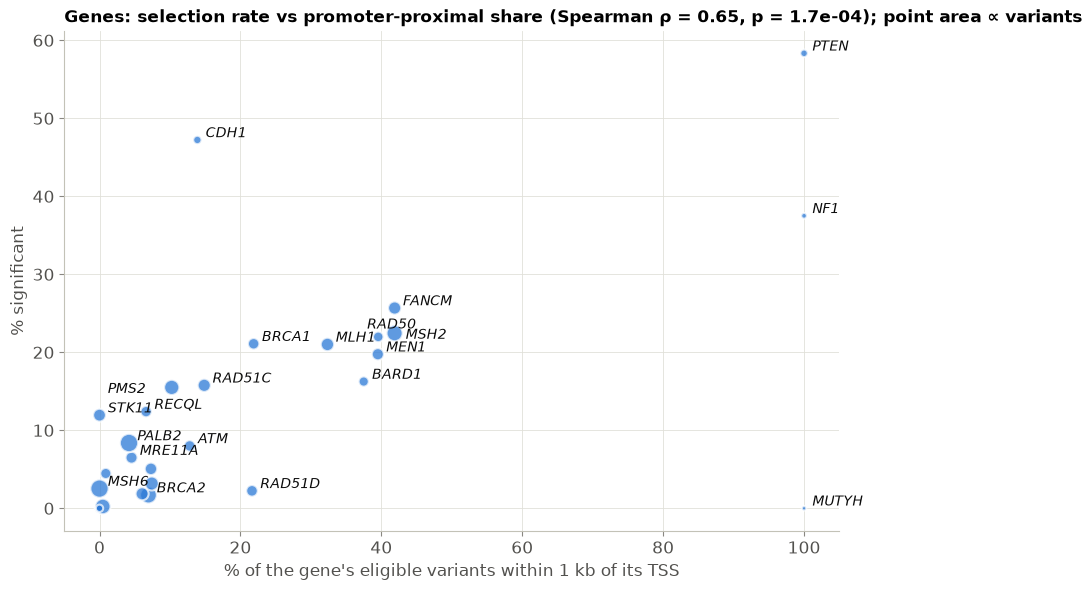

In [15]:
genes = eligible.groupby('gene_name').agg(n=('significant', 'size'), n_sig=('significant', 'sum'),
                                          near=('dist', lambda d: (d < 1000).mean()),
                                          median_dist=('dist', 'median'))
genes['pct_sig'] = 100 * genes.n_sig / genes.n
tot_sig, tot = genes.n_sig.sum(), genes.n.sum()
genes['p'] = [stats.fisher_exact([[s, n - s], [tot_sig - s, tot - n - tot_sig + s]])[1] for s, n in zip(genes.n_sig, genes.n)]
genes['q'] = multipletests(genes.p, method='fdr_bh')[1]
rho = stats.spearmanr(genes.near, genes.pct_sig)

NUDGE = {'RAD50': (-8, 6), 'MSH2': (8, -4), 'PMS2': (-46, -4)}
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(100 * genes.near, genes.pct_sig, s=np.sqrt(genes.n) * 6, color=BASE_C, alpha=0.75, edgecolor='white', lw=1.5)
for g, r in genes.iterrows():
    if r.n_sig >= 10 or r.pct_sig > 15 or r.near > 0.2:
        ax.annotate(g, (100 * r.near, r.pct_sig), xytext=NUDGE.get(g, (6, 2)), textcoords='offset points', fontsize=10,
                    style='italic', color=INK)
ax.set_xlabel("% of the gene's eligible variants within 1 kb of its TSS")
ax.set_ylabel('% significant')
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.set_title(f'Genes: selection rate vs promoter-proximal share (Spearman ρ = {rho.statistic:.2f}, '
             f'p = {rho.pvalue:.1e}); point area ∝ variants', fontsize=12)
save(fig, 'genes_rate_vs_proximity')
genes.sort_values('pct_sig', ascending=False).style.format(
    {'near': '{:.0%}', 'median_dist': '{:,.0f}', 'pct_sig': '{:.1f}', 'p': '{:.1e}', 'q': '{:.1e}'})

## 8. Direction: is anything specific to predicted *loss* of expression?

The selection keeps eligible variants with a large epithelial effect in the risk direction (decreased expression
for suppressors). Another 564 eligible variants have an equally large epithelial effect only in the *opposite*
direction. Comparing the two sets shows whether a feature marks "large predicted effect" in general or
the risk direction specifically.

In [16]:
big = eligible[eligible.significant | eligible.discordant_large].assign(
    detail_f=lambda d: d.detail.where(d.detail.isin(CODING_DETAIL), 'non-coding / other'),
    direction=lambda d: np.where(d.tss_signed < 0, 'upstream of TSS', 'downstream of TSS'),
    dnase_f=lambda d: np.where(d.dnase_any, 'in DNase peak', 'no DNase peak'),
    cpg_f=lambda d: np.where(d.cpg, 'CpG site', 'non-CpG'),
    tstv=lambda d: np.where(d.transition, 'transition', 'transversion'),
)
print(f'{big.significant.sum()} significant (loss) vs {(~big.significant).sum()} discordant (gain) large-effect variants')
direction = enrichment(big, 'significant', FEATURES)
print('median TSS distance: loss {:,.0f} bp, gain {:,.0f} bp'.format(
    big[big.significant].dist.median(), big[~big.significant].dist.median()))
direction[direction.q < 0.05].sort_values('q').style.format(fmt).hide(axis='index')

633 significant (loss) vs 564 discordant (gain) large-effect variants
median TSS distance: loss 415 bp, gain 845 bp


feature,level,n_sig,% sig,n_base,% base,OR,CI_lo,CI_hi,p,q
CpG,CpG site,183,28.9,67,11.9,3.00,2.21,4.08,2.2e-13,4.1e-12
CpG,non-CpG,450,71.1,497,88.1,0.33,0.25,0.45,2.2e-13,4.1e-12
substitution,T>C,122,19.3,159,28.2,0.61,0.47,0.80,2.9e-04,2.9e-03
ClinVar,pathogenic / likely,35,5.5,9,1.6,3.47,1.68,7.16,3.0e-04,2.9e-03
TSS distance,10-20 kb,79,12.5,40,7.1,1.86,1.25,2.76,1.9e-03,1.5e-02


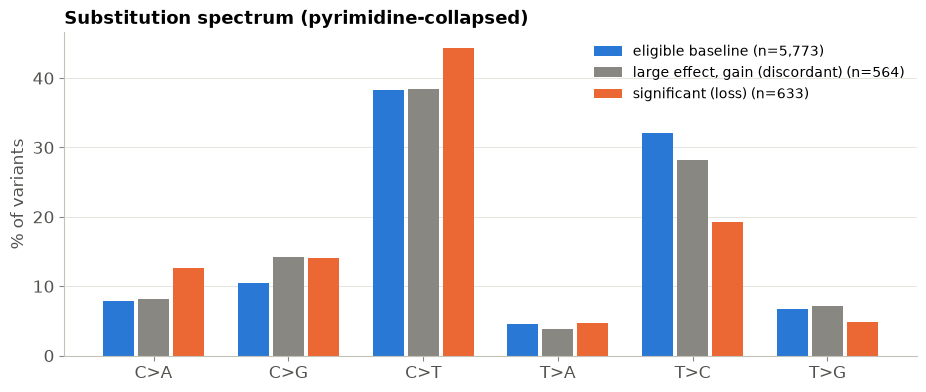

In [17]:
subs = ['C>A', 'C>G', 'C>T', 'T>A', 'T>C', 'T>G']
groups = {'eligible baseline': base, 'large effect, gain (discordant)': big[~big.significant],
          'significant (loss)': big[big.significant]}
colors = [BASE_C, ALT_C, SIG_C]
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.26
for i, ((lab, d), c) in enumerate(zip(groups.items(), colors)):
    frac = d.substitution.value_counts(normalize=True).reindex(subs).fillna(0) * 100
    ax.bar(np.arange(6) + (i - 1) * w, frac, width=w - 0.03, color=c, label=f'{lab} (n={len(d):,})')
ax.set_xticks(np.arange(6), subs)
ax.set_ylabel('% of variants')
ax.legend(frameon=False, fontsize=10)
ax.grid(axis='y', color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.set_title('Substitution spectrum (pyrimidine-collapsed)')
save(fig, 'substitution_spectrum')

## 9. How much do the features add beyond TSS distance?

Cross-validated AUC (5-fold, stratified) for logistic models of increasing size. If distance alone gets close to
the full model, the significant set is mostly "variants near a TSS of an eligible gene".

,AUC
TSS distance,0.862
gene,0.758
distance + gene,0.884
+ region,0.884
"+ sequence (subst., CpG, GC)",0.886
+ DNase,0.896
+ ClinVar,0.895


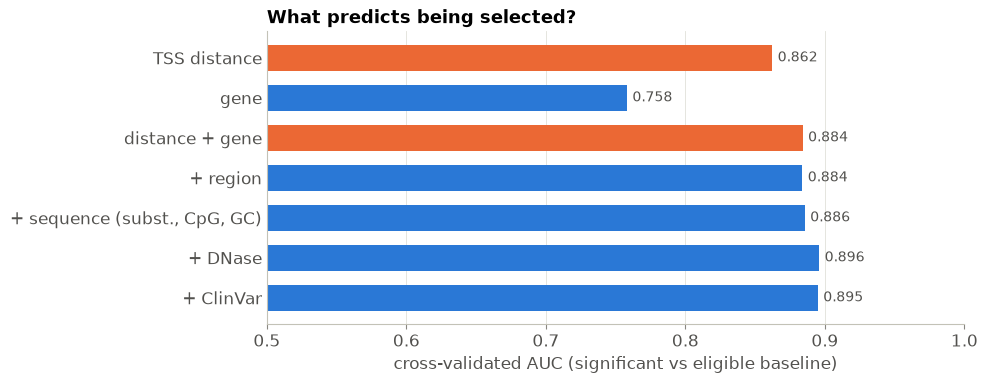

In [18]:
region_d = pd.get_dummies(e.region, prefix='region', drop_first=False).astype(float)
clin_d = pd.get_dummies(e.clinvar, prefix='cv').astype(float)
subs_d = pd.get_dummies(e.substitution, prefix='sub').astype(float)
gene_d = pd.get_dummies(e.gene_name, prefix='gene').astype(float)
dist_f = pd.DataFrame({'log_dist': e.log10_dist, 'log_dist2': e.log10_dist ** 2, 'upstream': (e.tss_signed < 0).astype(float)})
seq_f = pd.concat([subs_d, pd.DataFrame({'cpg': e.cpg.astype(float), 'gc': e.gc_100bp})], axis=1)
dnase_f = pd.DataFrame({'dnase_files': e.dnase_files.astype(float)})

MODELS = {
    'TSS distance': [dist_f],
    'gene': [gene_d],
    'distance + gene': [dist_f, gene_d],
    '+ region': [dist_f, gene_d, region_d],
    '+ sequence (subst., CpG, GC)': [dist_f, gene_d, region_d, seq_f],
    '+ DNase': [dist_f, gene_d, region_d, seq_f, dnase_f],
    '+ ClinVar': [dist_f, gene_d, region_d, seq_f, dnase_f, clin_d],
}
y = e.significant.values
cv = StratifiedKFold(5, shuffle=True, random_state=0)
auc = {}
for name, parts in MODELS.items():
    Xm = pd.concat(parts, axis=1).values
    Xm = (Xm - Xm.mean(0)) / (Xm.std(0) + 1e-9)
    p = cross_val_predict(LogisticRegression(max_iter=5000, C=1.0), Xm, y, cv=cv, method='predict_proba')[:, 1]
    auc[name] = roc_auc_score(y, p)
auc = pd.Series(auc)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(auc.index[::-1], auc[::-1], color=[SIG_C if 'distance' in k and k != 'gene' else BASE_C for k in auc.index[::-1]],
        height=0.65)
ax.bar_label(ax.containers[0], labels=[f'{v:.3f}' for v in auc[::-1]], padding=4, fontsize=10, color=SECONDARY)
ax.set_xlim(0.5, 1)
ax.set_xlabel('cross-validated AUC (significant vs eligible baseline)')
ax.grid(axis='x', color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0)
ax.set_title('What predicts being selected?')
save(fig, 'model_auc')
auc.round(3).to_frame('AUC')

## 10. Summary

In [19]:
def fmt_or(name):
    r = adj.set_index('feature').loc[name]
    return f'{name}: crude OR {r["crude OR"]:.2f} → adjusted {r["adj OR"]:.2f} (q = {r["adj q"]:.1g})'


print(f'eligible variants: {len(eligible):,}; significant: {len(sig)} ({len(sig) / len(eligible):.1%})')
print(f'median TSS distance: significant {sig.dist.median():,.0f} bp vs baseline {base.dist.median():,.0f} bp')
print(f'AUC distance alone {auc["TSS distance"]:.3f}; distance + gene {auc["distance + gene"]:.3f}; '
      f'all features {auc.iloc[-1]:.3f}')
for f in adj.feature:
    print(' ', fmt_or(f))

eligible variants: 6,406; significant: 633 (9.9%)
median TSS distance: significant 415 bp vs baseline 12,099 bp
AUC distance alone 0.862; distance + gene 0.884; all features 0.895
  promoter (≤1 kb): crude OR 8.85 → adjusted 0.99 (q = 0.9)
  5' UTR: crude OR 6.03 → adjusted 0.86 (q = 0.8)
  coding: crude OR 0.40 → adjusted 1.05 (q = 0.8)
  intron: crude OR 0.83 → adjusted 0.82 (q = 0.8)
  splice site / region: crude OR 0.99 → adjusted 1.21 (q = 0.8)
  missense: crude OR 0.61 → adjusted 1.05 (q = 0.8)
  synonymous: crude OR 0.74 → adjusted 0.96 (q = 0.8)
  stop gained: crude OR 0.59 → adjusted 1.32 (q = 0.8)
  upstream of TSS: crude OR 7.24 → adjusted 0.91 (q = 0.8)
  CpG site: crude OR 2.97 → adjusted 2.55 (q = 2e-13)
  transition: crude OR 0.74 → adjusted 0.86 (q = 0.5)
  CpG transition: crude OR 2.13 → adjusted 2.52 (q = 3e-10)
  GC ≥ 60% (±50 bp): crude OR 6.10 → adjusted 1.15 (q = 0.8)
  DNase peak (mammary epi): crude OR 11.21 → adjusted 2.94 (q = 3e-12)
  ClinVar pathogenic / lik

### Interpretation

**1. Distance to the TSS explains most of the difference.** Significant variants have a median distance of
415 bp to the ExPecto TSS, against 12.1 kb for the eligible baseline. Nearly half of the eligible variants within
500 bp of a TSS are significant, against 2% of those 10–20 kb away. Distance alone predicts selection with
cross-validated AUC 0.86. Adding gene raises this to 0.88, and all other features together add only about 0.01 more.

**2. Region and consequence enrichments are secondary to distance.** Promoter (OR 8.9), 5' UTR (6.0), upstream of
TSS (7.2) and high GC (6.1) are strongly enriched crude. Coding, missense and synonymous are depleted. Within gene ×
distance strata, all of these go to OR ≈ 1. The region classes add nothing beyond position. The coding
consequence is irrelevant, as expected for a sequence-to-expression model.

**3. Gene differences are also mostly about TSS proximity.** *PTEN*, *CDH1*, *FANCM*, *MSH2*, *MLH1*, *RAD50* and *MEN1* have
the highest rates and many variants near their TSS. *TP53*, *BRCA2*, *CHEK2* and *MSH6* have almost all their
variants >10 kb from the TSS and are depleted. Across genes, the share within 1 kb tracks the selection rate.

**4. Three features survive adjustment for distance and gene:**
- **CpG sites**: adjusted OR ≈ 2.5 (29% vs 12%). CpG transitions show the same effect. This is also the strongest
  difference between significant (predicted *loss*) variants and large-effect variants in the *gain* direction
  (OR 3.0, q = 4e-12). CpG-destroying mutations in GC-rich regulatory sequence typically break binding sites of
  CpG-preferring activators (SP/KLF, ETS, NRF1, CREB …). This fits a loss-of-expression prediction and is the
  most specific "risk-direction" signal here.
- **Mammary-epithelial DNase peaks**: adjusted OR ≈ 2.9 (49% vs 8% crude). Significant variants lie in chromatin
  that is open in the relevant cell type more often than other variants at the same distance. This is
  independent support from experimental data that ExPecto-sc never saw. Note that the gene × distance-bin
  adjustment is coarse, so some residual confounding by exact position is possible. The conditional-logit model
  with continuous log distance gives the same result (OR 1.19 per overlapping file).
- **ClinVar pathogenic / likely pathogenic**: no enrichment crude (5.5% vs 5.3%), but adjusted OR ≈ 2.0
  (q = 0.01) and 3.5-fold more frequent among loss than gain variants. The numbers are small (35 variants), and
  pathogenic labels near the TSS are mostly start-loss or stop-gain coding changes, so treat this as a lead to
  inspect variant by variant rather than a robust result.

**5. Nothing else distinguishes them.** VUS, benign and conflicting ClinVar classes, splice and intronic location,
and transition/transversion status do not differ after adjustment.

**Caveats.** The significant set is defined from ExPecto-sc predictions, so these results describe what the model
responds to (TSS proximity, CpG-rich open chromatin), not validated risk. The BRIDGES and ExPecto sets are
~83% coding, so promoter-proximal regulatory variation is sparsely sampled. The original selection code
misses *FAM175A*/*ABRAXAS1* (3 variants would qualify).